In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import nltk
import re
import string
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from sklearn.metrics import classification_report,precision_score,confusion_matrix


from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import PorterStemmer,WordNetLemmatizer


from sklearn.ensemble import RandomForestClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.feature_extraction.text import TfidfVectorizer
from wordcloud import WordCloud

nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')

[nltk_data] Error loading punkt: <urlopen error [Errno 11001]
[nltk_data]     getaddrinfo failed>
[nltk_data] Error loading stopwords: <urlopen error [Errno 11001]
[nltk_data]     getaddrinfo failed>
[nltk_data] Error loading wordnet: <urlopen error [Errno 11001]
[nltk_data]     getaddrinfo failed>


False

# Introduction

##### Title: Email Spam Classification Using Natural Language Processing

Email and text messages are an important part of modern communication, but users often receive unwanted or irrelevant messages. Spam messages can make it difficult to identify useful messages and may contain misleading or unwanted content.

Natural Language Processing (NLP) allows computers to process and understand human language. In this project, NLP techniques are used to preprocess text messages and convert them into numerical features that can be understood by machine learning algorithms.

The project develops a machine learning-based text classification system to classify messages into Ham, Spam, and Other categories. Different machine learning techniques are applied and their performance is evaluated using accuracy, confusion matrix, ROC curve, and AUC. The trained model is also tested with new, unseen messages to demonstrate real-world prediction.



In [2]:
df=pd.read_csv(r"c:\Users\nabee\Downloads\final_dataset (1).csv")

df

,label,text
0,0,annual physical scheduled 5 jun 2025 1015 loca...
1,0,please save e mail records dear craig congratu...
2,1,need urgent assistance donald williams esq 60 ...
3,2,megasize unit megadlk huge advancement mens he...
4,0,original message rodenburg eric enron sent mon...
...,...,...
515340,1,wallace tipton akstcanadyspharmamnsdgsanadysph...
515341,2,pottery barn kids order escapenumber dear dian...
515342,0,ticket 91 resolved please close satisfied
515343,2,hows tricks nipa ia


# Dataset Description

Dataset: final_dataset (1).csv

Dataset contains : 515,345 rows, 2 columns

| Column                | Description                                                                                                                |
|-----------------------|----------------------------------------------------------------------------------------------------------------------------|
| label                 | Class label (target variable) with three categories: 0 → Ham — legitimate/non-spam message,1 → Spam — unwanted or suspicious message , and 2-> advertising| message                                                                                                                                                    
| text                  | Text/email message used as the input for NLP classification                                                                |

### Data Inspection

1) Viewed first rows using "df.head"

2) Viewed last rows using "df.tail"

3) Checked shape using "df.shape"

4) Checked how many columns using "df.columns"

5) summary of the data structure "df.info()"

6) Null values using "df.isnull().sum()"

7) viewed dtypes "df.dtypes"

In [3]:
df.head()

,label,text
0,0,annual physical scheduled 5 jun 2025 1015 loca...
1,0,please save e mail records dear craig congratu...
2,1,need urgent assistance donald williams esq 60 ...
3,2,megasize unit megadlk huge advancement mens he...
4,0,original message rodenburg eric enron sent mon...


In [4]:
df.tail()

,label,text
515340,1,wallace tipton akstcanadyspharmamnsdgsanadysph...
515341,2,pottery barn kids order escapenumber dear dian...
515342,0,ticket 91 resolved please close satisfied
515343,2,hows tricks nipa ia
515344,0,office monday june escapenumberth need immedia...


In [5]:
df.columns

Index(['label', 'text'], dtype='object')

In [6]:
df.shape

(515345, 2)

In [7]:
print(df['label'].value_counts())

label
1    251970
0    177509
2     85866
Name: count, dtype: int64


In [8]:
print(df.groupby('label')['text'].first())

label
0    annual physical scheduled 5 jun 2025 1015 loca...
1    need urgent assistance donald williams esq 60 ...
2    megasize unit megadlk huge advancement mens he...
Name: text, dtype: object


In [9]:
df.dtypes

label     int64
text     object
dtype: object

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 515345 entries, 0 to 515344
Data columns (total 2 columns):
 #   Column  Non-Null Count   Dtype 
---  ------  --------------   ----- 
 0   label   515345 non-null  int64 
 1   text    515345 non-null  object
dtypes: int64(1), object(1)
memory usage: 7.9+ MB


In [11]:
df.isnull().sum()

label    0
text     0
dtype: int64

In [12]:
df.duplicated().sum()

np.int64(5912)

# EDA (Exploratory Data Analysis)

##### Visualize Class Distribution

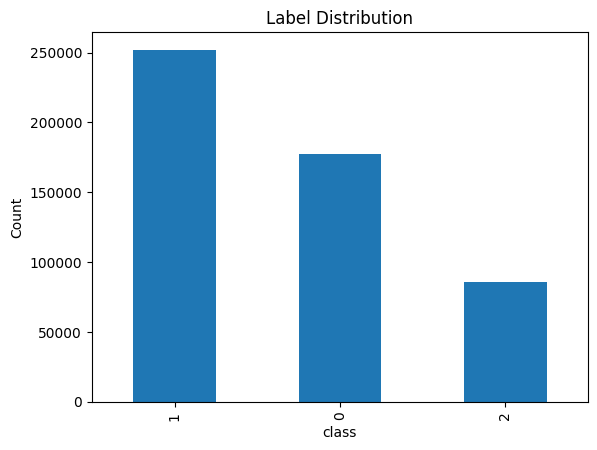

In [13]:
df['label'].value_counts().plot(kind='bar')
plt.title("Label Distribution")
plt.xlabel("class")
plt.ylabel("Count")
plt.show()

#### Class Distribution 

The bar chart shows the distribution of the three classes.
1) Class 1: Approximately 252,000 samples — the most frequent class.

2) Class 0: Approximately 178,000 samples.

3) Class 2: Approximately 86,000 samples — the least frequent class.

4) The classes are not equally distributed, indicating some class imbalance.

5) Label 2 has considerably fewer samples than Label 1.

In [14]:
df['text_length']=df['text'].astype(str).apply(len)

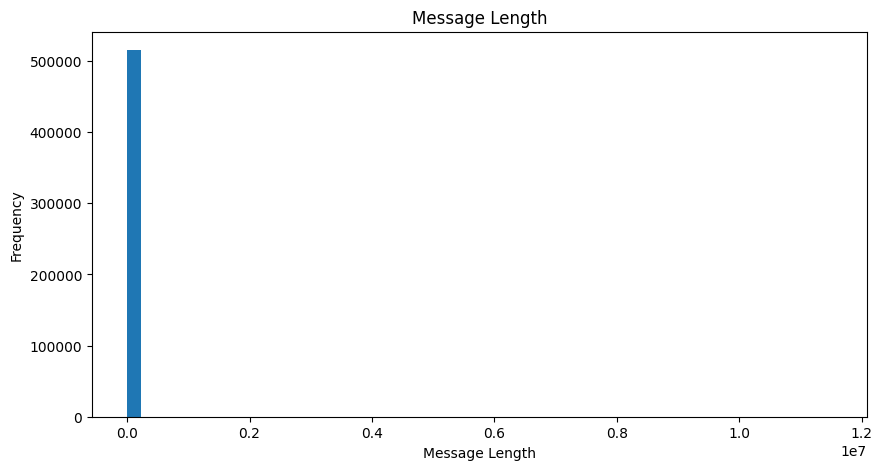

In [15]:
plt.figure(figsize=(10,5))

plt.hist(df['text_length'],bins=50)

plt.title("Message Length")
plt.xlabel("Message Length")
plt.ylabel('Frequency')
plt.show()

#### Text Length

1) Most messages have a short text length.

2) The distribution is highly right-skewed.

3) A small number of messages have very large lengths, creating the long tail.

4) This indicates that message lengths vary considerably across the dataset.





# Text Preprocessing

wordopt() is a text preprocessing function that cleans the text by removing unwanted information, tokenizing the text, removing stopwords, performing lemmatization, and returning the cleaned text for NLP analysis.


In [16]:

stop_words=set(stopwords.words('english'))
lemmatizer=WordNetLemmatizer()


def wordopt(text):
    text=str(text).lower()

    # Remove URLs
    text=re.sub(r'https:?//\S+|www\.\S+', '  ', text)

     # Remove HTML tags
    text=re.sub(r'<.*?>', ' ',text)
    text=re.sub(r'\[.*?\]','',text)

    # Remove words containing numbers
    text=re.sub(r'\w*\d\w*','',text)

        # Remove punctuation
    text=text.translate(str.maketrans(' ', ' ',string.punctuation))

       # Remove extra spaces 
    text=re.sub(r'\s+',' ',text).strip()

        # Tokenization
    words=word_tokenize(text)

    #  remove stop words 
    words=[word for word in words if word not in stop_words]

    # lemmatization
    words=[lemmatizer.lemmatize(word)for word in words]
    return ' '.join(words)



In [17]:
df['clean_text']=df['text'].apply(wordopt)

This statement applies the wordopt() function to each text in the text column and stores the cleaned, preprocessed text in a new column called clean_text. The cleaned text is then used for further NLP tasks such as TF-IDF, Word Cloud, and sentiment classification.

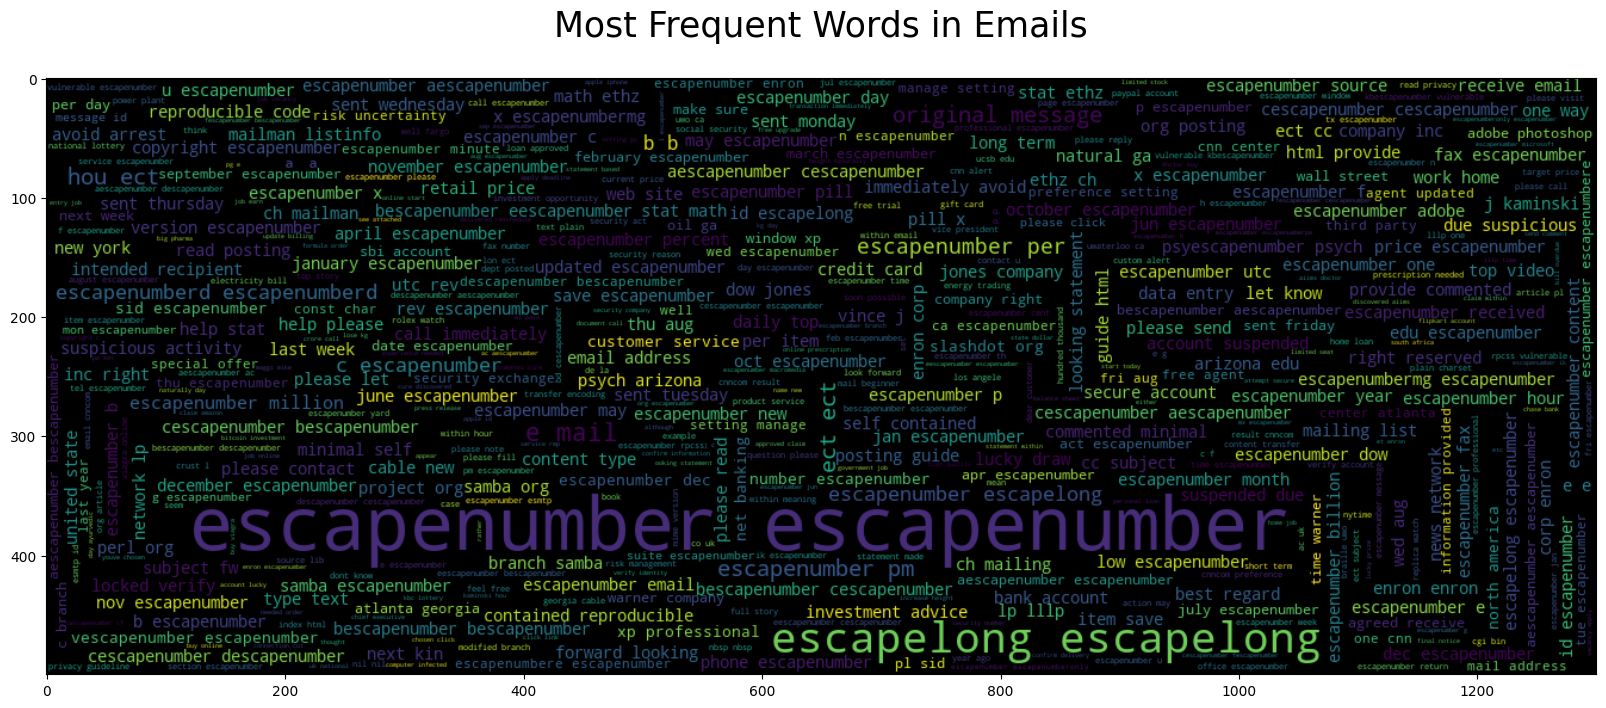

In [18]:
text_com=' '.join(df['clean_text'].dropna().astype(str).str.strip())

if not  text_com.strip():
    print("No words found the dataset")
else:
    plt.figure(figsize=(20,15), facecolor='None')
    wordcloud=WordCloud(max_words=500,
                        width=1300,
                        height=500).generate(text_com)
    plt.imshow(wordcloud, interpolation='bilinear')
    plt.axis=('off') 
    plt.title("Most Frequent Words in Emails", fontsize=25, pad=30)
    plt.show()


#### Word Cloud – Observation

The word cloud visualizes the most frequently occurring words in the email dataset. Larger words indicate higher frequency. Common terms such as email, message, account, subject, mail, and company appear prominently. This visualization helps understand the main characteristics of the email text.

#  Feature Engineering (Text Vectorization) 

##### Training the variables

 To select the**Target and independent variables** in X 
 
 and Y.The target variable is **label**, and the 
 
 remaining features are used as input variables. The 
 
 data is then split into training and testing sets.


In [19]:
x=df['text']
x

0         annual physical scheduled 5 jun 2025 1015 loca...
1         please save e mail records dear craig congratu...
2         need urgent assistance donald williams esq 60 ...
3         megasize unit megadlk huge advancement mens he...
4         original message rodenburg eric enron sent mon...
                                ...                        
515340    wallace tipton akstcanadyspharmamnsdgsanadysph...
515341    pottery barn kids order escapenumber dear dian...
515342            ticket 91 resolved please close satisfied
515343                                  hows tricks nipa ia
515344    office monday june escapenumberth need immedia...
Name: text, Length: 515345, dtype: object

In [20]:
y=df['label']
y

0         0
1         0
2         1
3         2
4         0
         ..
515340    1
515341    2
515342    0
515343    2
515344    0
Name: label, Length: 515345, dtype: int64

In [21]:
x_train,x_test,y_train,y_test=train_test_split(x,y,random_state=42,test_size=0.2, stratify=y)

#### Feature Extraction used TF(Term Frequency) IDF (Inverse Document Frequency) vectorizer

To convert the text to numerical formats 

In [22]:
from sklearn.feature_extraction.text import TfidfVectorizer

In [50]:

# sublinear_tf=True: raw frequency of a word.
# min_df means minimum document frequency.


vector=TfidfVectorizer(
    max_features=50000,
    min_df=2
    sublinear_tf=True
)
xv_train=vector.fit_transform(x_train)
xv_test=vector.transform(x_test)

SyntaxError: invalid syntax. Perhaps you forgot a comma? (3604812837.py, line 7)

#### Model Selection 
 
 machine learning model is selected and trained using 
 
 the training data, and its performance is evaluated on 
 
 the test data.

In [24]:
lr=LogisticRegression(max_iter=1000)
lr.fit(xv_train,y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`mul

In [25]:
y_pred=lr.predict(xv_test)

In [26]:
accuracy=accuracy_score(y_test,y_pred)
accuracy



0.9588431051043476

In [27]:
dt=DecisionTreeClassifier()
dt.fit(xv_train,y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the curre

In [28]:
y_pred=dt.predict(xv_test)

In [29]:
accu=accuracy_score(y_test,y_pred)
accu

0.9445031968875219

In [30]:
from sklearn.naive_bayes import MultinomialNB

naive=MultinomialNB()

In [31]:
naive.fit(xv_train,y_train)

,"alpha alpha: float or array-like of shape (n_features,), default=1.0Additive (Laplace/Lidstone) smoothing parameter(set alpha=0 and force_alpha=True, for no smoothing).",1.0
,"force_alpha force_alpha: bool, default=TrueIf False and alpha is less than 1e-10, it will set alpha to1e-10. If True, alpha will remain unchanged. This may causenumerical errors if alpha is too close to 0... versionadded:: 1.2.. versionchanged:: 1.4 The default value of `force_alpha` changed to `True`.",True
,"fit_prior fit_prior: bool, default=TrueWhether to learn class prior probabilities or not.If false, a uniform prior will be used.",True
,"class_prior class_prior: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None


In [32]:
y_pred=naive.predict(xv_test)

In [44]:
accur=accuracy_score(y_test,y_pred)
accur

0.9367317040041138

In [34]:
from sklearn.metrics import classification_report, confusion_matrix

In [45]:
print(classification_report(y_test,y_pred))
cm=confusion_matrix(y_test,y_pred)
print(cm,"confusion_metrics:")

              precision    recall  f1-score   support

           0       0.97      0.97      0.97     35502
           1       0.99      0.91      0.95     50394
           2       0.77      0.93      0.84     17173

    accuracy                           0.94    103069
   macro avg       0.91      0.94      0.92    103069
weighted avg       0.94      0.94      0.94    103069

[[34554   211   737]
 [  360 45966  4068]
 [  869   276 16028]] confusion_metrics:


Logistic Regression achieved an accuracy of 95%. Classes 0 and 1 achieved F1-scores of 97% and 96%, respectively, while Class 2 achieved 85%. The macro-average F1-score was 93%, indicating that the model performs well across all three classes despite the class imbalance.

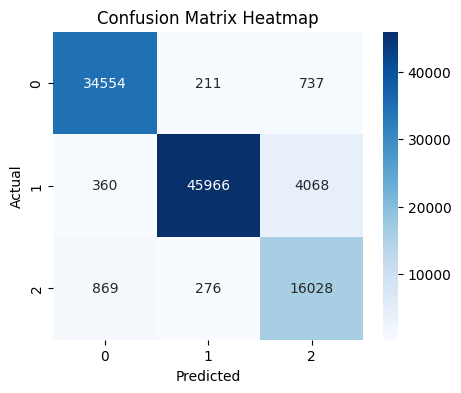

In [46]:
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix Heatmap")

plt.show()



The confusion matrix shows that the model performs well across all three classes, with most predictions concentrated along the diagonal. The overall accuracy is approximately 94.45%. However, Class 2 has comparatively more misclassifications, particularly with Class 1.

In [47]:
from sklearn.metrics import auc,roc_curve

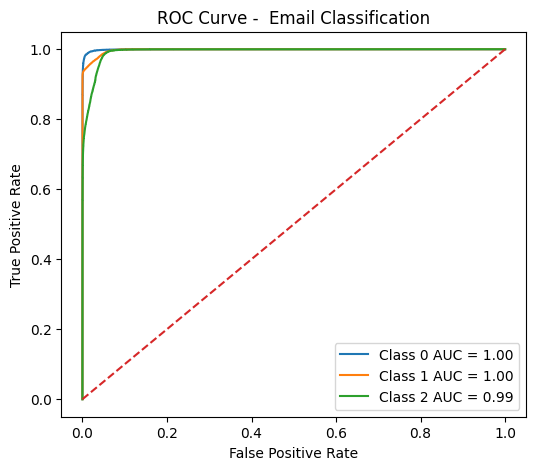

In [48]:



# predict probability

y_prob=lr.predict_proba(xv_test)


plt.figure(figsize=(6,5))

for i in range(3):
    fpr,tpr, _ = roc_curve(
        y_test == i,
        y_prob[:,i]
    )
    roc_auc =auc(fpr,tpr)

    plt.plot(fpr,tpr, label=f"Class {i} AUC = {roc_auc:.2f}")

#plot roc  curve
plt.plot([0,1],[0,1],linestyle='--')
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve -  Email Classification")
plt.legend()
plt.show()


1) The ROC curve shows the performance of the email classification model at different classification thresholds.

2) X-axis: False Positive Rate (FPR)

3) Y-axis: True Positive Rate (TPR)

4) The red dashed diagonal line represents random classification, with AUC = 0.50.

5) The ROC curves for Class 0, Class 1, and Class 2 are very close to the top-left corner, indicating excellent classification performance.

In [49]:
pt=[]   
for i in [lr,dt,naive]:
    i.fit(xv_train,y_train)
    pt.append(round(accuracy_score(y_test,i.predict(xv_test))* 100 , 2))  
print(pt)    

[95.88, 94.46, 93.67]


This loops through Logistic Regression and Decision Tree, predicts the test data, calculates each model's accuracy, converts it to a percentage, and stores the results in pt.

In [ ]:
# show the complete text.
pd.set_option('display.max_colwidth',None)

In [41]:
x.head(4)

0                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                       

In [42]:
y.head(4)

0    0
1    0
2    1
3    2
Name: label, dtype: int64

In [51]:
sample=["""annual physical scheduled 5 jun 2025 1015 location chicago"""]
sample_vector= vector.transform(sample)
result=lr.predict(sample_vector)
print(result)

if (result == 0):
    print("Ham")
elif (result == 1):
    print("Spam")
else:
    print("Other")        

[0]
Ham


# Email Spam/Ham Classification — Project Documentation


1. **Project Title**

Email Spam/Ham Classification Using Natural Language Processing and Machine Learning

2. **Project Objective**

The objective of this project is to develop a machine learning model that can automatically classify email/text messages into different categories such as:

Ham (Class 0) – legitimate/normal messages
Spam (Class 1) – unwanted or spam messages
Other (Class 2) – other message categories

The project uses Natural Language Processing (NLP) to convert text data into numerical features and Logistic Regression to perform classification.

3. **Dataset** 

Dataset contains : 515,345 rows, 2 columns

| Column                | Description                                                                                                                |
|-----------------------|----------------------------------------------------------------------------------------------------------------------------|
| label                 | Class label (target variable) with three categories: 0 → Ham — legitimate/non-spam message,1 → Spam — unwanted or suspicious message , and 2-> advertising| message                                                                                                                                                    
| text                  | Text/email message used as the input for NLP classification  


4. **Technologies Used**

Python

Pandas – data manipulation

NumPy – numerical operations

NLTK – NLP preprocessing

Scikit-learn – machine learning

Matplotlib – visualization

Jupyter Notebook / VS Code



5. **NLP Preprocessing**

The text data was processed before training the machine learning model.

The main preprocessing steps include:

1) Convert text to lowercase

2) Remove unwanted punctuation/symbols

3) Tokenization

4) Remove stop words

5) Text vectorization

The purpose of preprocessing is to convert raw text into a cleaner format that can be used by the machine learning model.

6. **Text Vectorization**

Machine learning algorithms cannot directly understand text.

Therefore, the text was converted into numerical features using a vectorizer.

Raw Text
   ↓
Preprocessing
   ↓
Vectorization
   ↓
Numerical Features
   ↓
Machine Learning Model

7. **Train-Test Split**

The dataset was divided into:

Training data → used to train the model
Testing data → used to evaluate the model

The training data teaches the model patterns in the messages, while the test data checks how well the model performs on unseen data.

8. **Machine Learning Models**

The project evaluates machine learning classification models such as:

Logistic Regression:

Logistic Regression was used as the main classification model.

Decision Tree:

A Decision Tree was also used for comparison.

9. **Model Evaluation**

The models were evaluated using:

Accuracy
Confusion Matrix
ROC Curve
AUC

10. **New Message Prediction**

The trained model was also tested using a new message:

"annual physical scheduled 5 jun 2025 1015 location chicago"

This means the model classified the new message as Class 0 (Ham).

New Message
     ↓
Vectorizer
     ↓
Numerical Representation
     ↓
Logistic Regression
     ↓
Class 0
     ↓
Ham

11. **Results**

The model achieved approximately 94.45% overall accuracy on the test set.

The confusion matrix shows that most predictions were correct, while the ROC-AUC results show strong classification performance across the three classes.

12. **Conclusion**

This project demonstrates how Natural Language Processing and Machine Learning can be used to automatically classify text messages.

The workflow included:

Dataset
   ↓
Data Cleaning
   ↓
NLP Preprocessing
   ↓
Text Vectorization
   ↓
Train-Test Split
   ↓
Model Training
   ↓
Prediction
   ↓
Evaluation
   ↓
New Message Classification

Developed an NLP-based email classification system to classify messages into Ham, Spam, and Other categories. Performed text preprocessing and vectorization, trained Logistic Regression and Decision Tree models, and evaluated performance using accuracy, confusion matrix, ROC curve, and AUC. The Logistic Regression model achieved approximately 94.45% test accuracy.